<a href="https://colab.research.google.com/github/madeeha-noor/Student-Success-Early-Warning/blob/main/notebooks/03_transformations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 03 Transformations
Prepare the data for modelling: encode the code columns, scale the numbers, and reduce with PCA

In [14]:
!pip install -q ucimlrepo

In [15]:
from ucimlrepo import fetch_ucirepo
import pandas as pd
import numpy as np

ds = fetch_ucirepo(id=697)
df = pd.concat([ds.data.features, ds.data.targets], axis=1)
df.columns = df.columns.str.strip()
print(df.shape)

(4424, 37)


In [16]:
target_col = 'Target'

code_cols = ['Marital Status', 'Application mode', 'Course', 'Previous qualification',
             'Nacionality', "Mother's qualification", "Father's qualification",
             "Mother's occupation", "Father's occupation"]

binary_cols = ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
               'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']

numeric_cols = [c for c in df.columns if c not in code_cols + binary_cols + [target_col]]

print('Code columns:', len(code_cols))
print('Yes/no columns:', len(binary_cols))
print('Numeric columns:', len(numeric_cols))
print(numeric_cols)

Code columns: 9
Yes/no columns: 8
Numeric columns: 19
['Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP']


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler

X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_test.shape)

pre = ColumnTransformer([
    ('codes', OneHotEncoder(handle_unknown='ignore'), code_cols),
    ('numbers', RobustScaler(), numeric_cols),
    ('binary', 'passthrough', binary_cols)],
    sparse_threshold=0)

X_train_t = pre.fit_transform(X_train)
X_test_t = pre.transform(X_test)
print(X_train_t.shape, X_test_t.shape)

(3539, 36) (885, 36)
(3539, 236) (885, 236)


In [18]:
names = pre.get_feature_names_out()
print(names[:3])
print(names[-3:])

age = X_train_t[:, list(names).index('numbers__Age at enrollment')]
print('Age after scaling -> median:', np.median(age).round(2),
      ' min:', age.min().round(2), ' max:', age.max().round(2))

['codes__Marital Status_1' 'codes__Marital Status_2'
 'codes__Marital Status_3']
['binary__Gender' 'binary__Scholarship holder' 'binary__International']
Age after scaling -> median: 0.0  min: -0.5  max: 8.33


## Encoding and Scaling
- The 36 features fall into 3 groups: 9 code columns, 8 yes/no columns and 19 numeric columns
- The 9 code columns are one-hot encoded, so a model does not treat course codes as quantites
- Numeric columns are scaled with RobustScaler (median and IQR), becuase we kept the outliers found in Notebbok 2
- Yes/no columns are left unchanged
- We split the data 80/20 (stratifed, seed 42) and fit the transformer on the training part only, so no test information leaks in
- Result: 236 columns (209 one-hot + 19 numeric + 8 yes/no) for 3539 training and 885 test students. The 9 columns code could give up to 220 one-hot columns, but 11 rare categories do not appear in the training part
- Age after scaling: medain 0.0, range -0.5 to 8.33. The oldest students are still outliers, but they no longer distort the scale for everyone else

In [19]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(random_state=42)
pca.fit(X_train_t)

cum = np.cumsum(pca.explained_variance_ratio_)
print('Total components:', len(cum))
print('First 3 components keep:', (pca.explained_variance_ratio_[:3] * 100).round(1), '%')
for goal in [0.80, 0.90, 0.95]:
    print(f"{goal:.0%} of the information needs {np.argmax(cum >= goal) + 1} components")

Total components: 236
First 3 components keep: [36.6 20.3  5.8] %
80% of the information needs 11 components
90% of the information needs 26 components
95% of the information needs 42 components
Total components: 236
First 3 components keep: [36.6 20.3  5.8] %
80% of the information needs 11 components
90% of the information needs 26 components
95% of the information needs 42 components


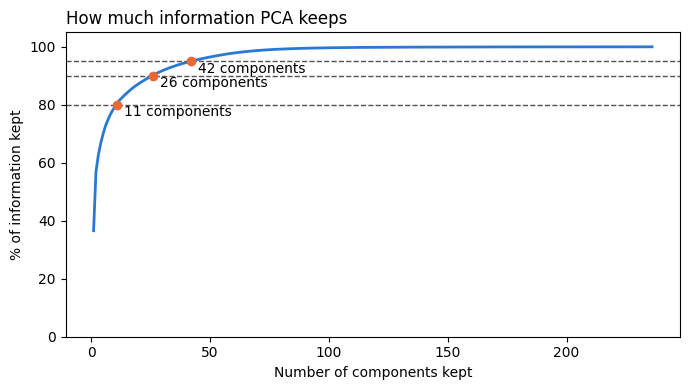

In [20]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(cum) + 1), cum * 100, color='#2a78d6', linewidth=2)
for goal in [0.80, 0.90, 0.95]:
    k = np.argmax(cum >= goal) + 1
    ax.axhline(goal * 100, color='#52514e', linestyle='--', linewidth=1)
    ax.plot(k, goal * 100, 'o', color='#eb6834')
    ax.text(k + 3, goal * 100 - 4, f"{k} components", fontsize=10)
ax.set_xlabel('Number of components kept')
ax.set_ylabel('% of information kept')
ax.set_title('How much information PCA keeps', loc='left')
ax.set_ylim(0, 105)
plt.tight_layout()
plt.show()

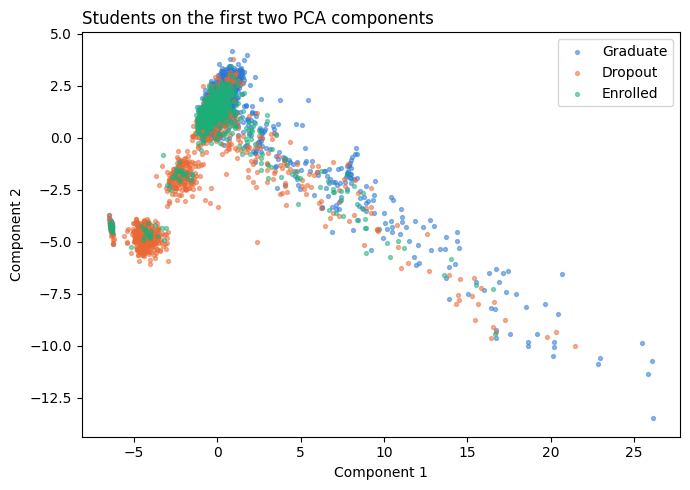

In [21]:
COLORS = {'Graduate': '#2a78d6', 'Dropout': '#eb6834', 'Enrolled': '#1baf7a'}
pca2 = PCA(n_components=2, random_state=42)
Z = pca2.fit_transform(X_train_t)

fig, ax = plt.subplots(figsize=(7, 5))
for outcome in ['Graduate', 'Dropout', 'Enrolled']:
    mask = (y_train == outcome).values
    ax.scatter(Z[mask, 0], Z[mask, 1], s=8, alpha=0.5, color=COLORS[outcome], label=outcome)
ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')
ax.set_title('Students on the first two PCA components', loc='left')
ax.legend()
plt.tight_layout()
plt.show()

## PCA
- We fitted PCA on the 236 training columns. The first three components keep 36.6%, 20.3% and 5.8% of the information
- 11 components keep 80%, 26 keep 90% and 42 keep 95%, so PCA compresses the data a lot (from 236 columns to about 26 for 90%)
- On the first two components, most graduates and enrolled students form one dense group, while many dropouts form separate groups at the bottom left. The outcomes overlap in the middle, so two components do not separate them fully
- Limitation: PCA follows the columns with the most spread, so the scaled numeric columns (grades and unit counts) probably dominate, and the many one-hot columns count for less
- We will use PCA mainly for clustering and for plots

In [22]:
pc1 = pd.Series(np.abs(pca.components_[0]), index=names).sort_values(ascending=False)
print(pc1.head(8).round(2))

numbers__Curricular units 1st sem (credited)       0.55
numbers__Curricular units 2nd sem (credited)       0.44
numbers__Curricular units 2nd sem (grade)          0.32
numbers__Curricular units 1st sem (grade)          0.31
numbers__Curricular units 1st sem (enrolled)       0.30
numbers__Curricular units 2nd sem (enrolled)       0.25
numbers__Curricular units 1st sem (approved)       0.25
numbers__Curricular units 1st sem (evaluations)    0.20
dtype: float64
